In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp17: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, tensorflow as tf, matplotlib.pyplot as plt
np.random.seed(17); tf.random.set_seed(17)
text=("deep learning models learn patterns from sequential data. " * 300)
chars=sorted(set(text)); c2i={c:i for i,c in enumerate(chars)}
encoded=np.array([c2i[c] for c in text]); seq=40
X=np.array([encoded[i:i+seq] for i in range(len(encoded)-seq-1)])
y=encoded[seq+np.arange(len(X))]
X=tf.keras.utils.to_categorical(X,len(chars)); y=tf.keras.utils.to_categorical(y,len(chars))
X=X[:2500]; y=y[:2500]
def train_model(clipnorm=None,clipvalue=None):
 opt=tf.keras.optimizers.Adam(learning_rate=.03,clipnorm=clipnorm,clipvalue=clipvalue)
 m=tf.keras.Sequential([tf.keras.layers.Input((seq,len(chars))),tf.keras.layers.SimpleRNN(64),tf.keras.layers.Dense(len(chars),activation="softmax")])
 loss_fn=tf.keras.losses.CategoricalCrossentropy(); norms=[]; losses=[]
 for start in range(0,len(X),64):
    xb=X[start:start+64]; yb=y[start:start+64]
    with tf.GradientTape() as tape: loss=loss_fn(yb,m(xb,training=True))
    grads=tape.gradient(loss,m.trainable_variables)
    norms.append(float(tf.linalg.global_norm(grads))); losses.append(float(loss))
    opt.apply_gradients(zip(grads,m.trainable_variables))
 return m,np.array(norms),np.array(losses)
settings=[("No clipping",None,None),("clipnorm=1",1,None),("clipvalue=.5",None,.5)]
results={}
for name,cn,cv in settings:
 _,gn,ls=train_model(cn,cv); results[name]=(gn,ls)
 print(name,"max gradient norm:",round(float(np.max(gn)),4),"final loss:",round(float(ls[-1]),4))
fig,ax=plt.subplots(1,2,figsize=(12,4))
for name,(gn,ls) in results.items(): ax[0].plot(gn,label=name); ax[1].plot(ls,label=name)
ax[0].set_title("Global gradient norm"); ax[1].set_title("Training loss")
for a in ax: a.set_xlabel("Training step"); a.legend(); a.grid()
plt.tight_layout(); plt.show()

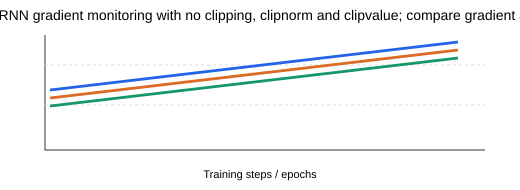

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.